# 2026 — Engram: Conditional Memory via Hashed N-gram Lookup

**Paper:** DeepSeek-AI, *"Conditional Memory via Scalable Lookup: A New Axis of Sparsity for Large Language Models"* (Engram, arXiv 2601.07372, January 2026). It builds on old ideas: N-gram language models, hashed embeddings (the "hashing trick"), and product-key memories (2019).

MoE (notebook 64) is one kind of sparsity: **conditional computation**, where each token activates a few experts. Engram adds a second kind: **conditional memory**. Much of what an LLM learns is static local patterns ("New York", "in order to", common code idioms), and the early layers spend compute rebuilding them. Engram simply *looks them up*:

1. **Tokenizer compression:** map token IDs to canonical IDs, e.g. lowercase and Unicode-normalised (about 23% fewer IDs for a 128K vocabulary)
2. **N-gram keys:** for each position, the suffix 2-gram and 3-gram of canonical IDs
3. **Hashing:** $K$ hash heads per order index large embedding tables, $e_{t,n,k} = E_{n,k}[\phi_{n,k}(g_{t,n})]$; concatenate everything into $e_t$
4. **Context-aware gate:** the current hidden state decides whether to trust the memory,
$$\alpha_t = \sigma\!\Big(\frac{\operatorname{RMSNorm}(h_t)^\top \operatorname{RMSNorm}(W_K e_t)}{\sqrt d}\Big),\qquad \tilde v_t = \alpha_t\, W_V e_t$$
5. **Causal depthwise conv** (kernel 4, dilation = max N, zero-initialised), $Y = \operatorname{SiLU}(\operatorname{Conv}(\operatorname{RMSNorm}(\tilde V))) + \tilde V$; add $Y$ to the residual stream early in the network (DeepSeek: layers 2 and 15 of 30)

The lookup depends only on token IDs, so the tables can live in **CPU memory** and be prefetched; a 100B-parameter table cost under 3% throughput. At 27B parameters, moving about 20–25% of the sparse parameter budget from MoE experts into Engram improved every benchmark (e.g. BBH +5.0, MMLU +3.0) and long-context retrieval (multi-query needle-in-a-haystack 84.2 → 97.0).

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


## Tokenizer compression and hashed N-gram keys
Our "tokens" are characters, so canonicalisation is lowercasing.

In [3]:
canon_map = torch.tensor([stoi.get(c.lower(), stoi[c]) for c in chars], device=device)   # surjective P: V -> V'
print(f"{V} token ids -> {len(set(canon_map.tolist()))} canonical ids")

class NgramHasher(nn.Module):
    """Multiplicative-XOR hashing of suffix n-grams of canonical ids into K tables per order (prime sizes)."""
    def __init__(self, orders=(2, 3), heads=2, sizes=(4093, 8191), dim=32):
        super().__init__()
        self.orders, self.heads = orders, heads
        g = torch.Generator().manual_seed(0)
        self.register_buffer("mult", torch.randint(1, 2 ** 20, (len(orders), heads, max(orders)), generator=g) * 2 + 1)   # odd multipliers
        self.sizes = sizes
        self.tables = nn.ModuleList([nn.Embedding(sizes[k % len(sizes)], dim) for _ in orders for k in range(heads)])
        for t in self.tables: nn.init.normal_(t.weight, std=0.02)
        self.out_dim = len(orders) * heads * dim
    def forward(self, ids):                                                           # ids: (B, T) canonical
        B, T = ids.shape; outs = []; i = 0
        for oi, n in enumerate(self.orders):
            grams = torch.stack([F.pad(ids, (j, 0), value=0)[:, :T] for j in range(n)], -1)   # (B, T, n): x_t, x_{t-1}, ...
            for k in range(self.heads):
                h = torch.zeros(B, T, dtype=torch.long, device=ids.device)
                for j in range(n): h = h ^ (grams[..., j] * self.mult[oi, k, j])
                outs.append(self.tables[i](h % self.tables[i].num_embeddings)); i += 1
        return torch.cat(outs, -1)                                                    # e_t: concatenation of all lookups

31 token ids -> 28 canonical ids


In [4]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class Engram(nn.Module):
    def __init__(self, d, max_n=3):
        super().__init__()
        self.hasher = NgramHasher()
        self.W_K, self.W_V = nn.Linear(self.hasher.out_dim, d, bias=False), nn.Linear(self.hasher.out_dim, d, bias=False)
        self.n_h, self.n_k, self.n_v = RMSNorm(d), RMSNorm(d), RMSNorm(d)
        self.conv = nn.Conv1d(d, d, 4, groups=d, dilation=max_n, padding=0)
        nn.init.zeros_(self.conv.weight); nn.init.zeros_(self.conv.bias)              # zero init: starts as identity on V~
        self.pad = 3 * max_n; self.d = d; self.enabled = True; self.last_gate = None
    def forward(self, h, ids):
        e = self.hasher(canon_map[ids])
        k, v = self.W_K(e), self.W_V(e)
        alpha = torch.sigmoid((self.n_h(h) * self.n_k(k)).sum(-1, keepdim=True) / math.sqrt(self.d))   # context-aware gate
        self.last_gate = alpha.detach()
        vt = alpha * v
        y = F.silu(self.conv(F.pad(self.n_v(vt).transpose(1, 2), (self.pad, 0)))).transpose(1, 2) + vt
        return y if self.enabled else torch.zeros_like(y)

class Block(nn.Module):
    def __init__(self, d, heads=4):
        super().__init__()
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d); self.qkv, self.o, self.h = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False), heads
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        x = x + self.o(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.n2(x))

class LM(nn.Module):
    def __init__(self, engram_layers=(), d=96, n_layers=4, ctx=128):
        super().__init__()
        self.ctx = ctx; self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.blocks = nn.ModuleList([Block(d) for _ in range(n_layers)])
        self.engrams = nn.ModuleDict({str(i): Engram(d) for i in engram_layers})       # inserted before block i
        self.ln, self.head = RMSNorm(d), nn.Linear(d, V, bias=False)
    def forward(self, idx):
        h = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        for i, b in enumerate(self.blocks):
            if str(i) in self.engrams: h = h + self.engrams[str(i)](h, idx)            # H <- H + Y, then attention + MLP
            h = b(h)
        return self.head(self.ln(h))

## Train with and without Engram
Engram tables use Adam with 5× the learning rate and no weight decay, as in the paper. The backbone is identical, so the compute per token is nearly the same: the extra cost is a few lookups and small projections.

baseline               final val loss 0.2348 | table params 0 | 37s


+ Engram at layer 1    final val loss 0.2166 | table params 786,176 | 38s


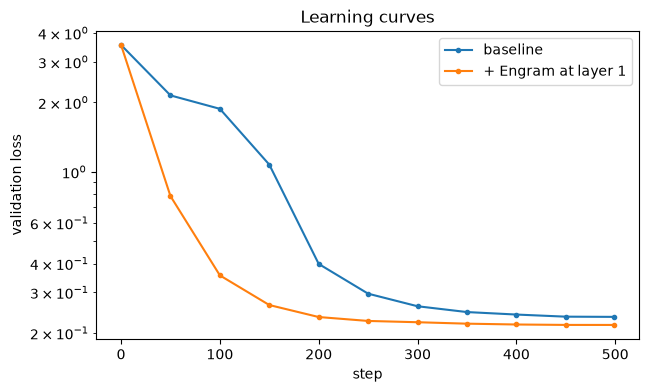

In [5]:
def get_batch(src, B=32):
    ix = torch.randint(0, len(src) - 129, (B,), device=device)
    return src[ix[:, None] + torch.arange(128, device=src.device)], src[ix[:, None] + torch.arange(1, 129, device=src.device)]

@torch.no_grad()
def val_loss(m):
    m.eval(); g = torch.Generator().manual_seed(7); out = []
    for _ in range(10):
        ix = torch.randint(0, len(val_data) - 129, (32,), generator=g).to(device)
        x = val_data[ix[:, None] + torch.arange(128, device=val_data.device)]; y = val_data[ix[:, None] + torch.arange(1, 129, device=val_data.device)]
        out.append(F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item())
    m.train(); return float(np.mean(out))

def train(engram_layers, steps=500, lr=2e-3):
    seed_everything(0); m = LM(engram_layers).to(device)
    table_params = [p for n, p in m.named_parameters() if "tables" in n]
    other = [p for n, p in m.named_parameters() if "tables" not in n]
    opt = torch.optim.AdamW([{"params": other, "lr": lr, "weight_decay": 0.1}, {"params": table_params, "lr": 5 * lr, "weight_decay": 0.0}])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, [lr, 5 * lr], total_steps=steps, pct_start=0.1); curve = []
    for s in range(steps):
        x, y = get_batch(train_data); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
        if s % 50 == 0 or s == steps - 1: curve.append((s, val_loss(m)))
    return m, curve

runs = {}
for name, layers in [("baseline", ()), ("+ Engram at layer 1", (1,))]:
    t0 = time.time(); runs[name] = train(layers)
    m = runs[name][0]
    n_tab = sum(p.numel() for n, p in m.named_parameters() if "tables" in n)
    print(f"{name:22s} final val loss {runs[name][1][-1][1]:.4f} | table params {n_tab:,} | {time.time() - t0:.0f}s")
plt.figure(figsize=(7, 4))
for name, (_, c) in runs.items(): plt.plot(*zip(*c), marker=".", label=name)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("validation loss"); plt.legend(); plt.title("Learning curves"); plt.show()

## What did the memory learn?
**1. Ablation:** switch the Engram output off at inference. The model has come to rely on it. (The paper found factual knowledge depends on Engram most, keeping only 29–44% of performance without it, while reading comprehension kept 81–93%.)

**2. The gate:** which positions open the memory gate $\alpha_t$? Expect high values where the preceding characters strongly determine what comes next, such as inside frequent words.

val loss with Engram 0.2166 | Engram switched off at inference 3.5813


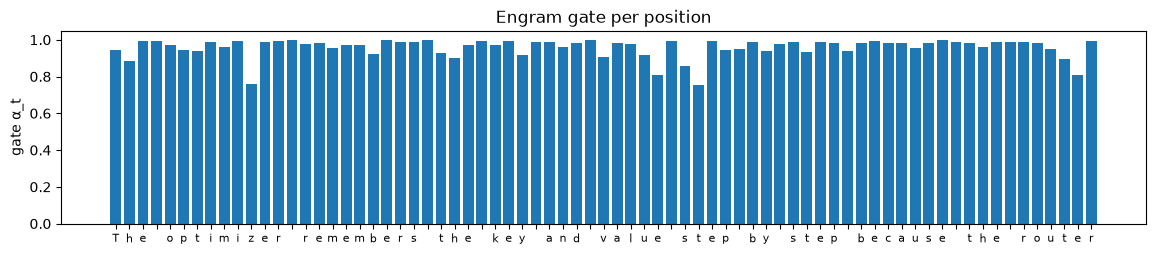

In [6]:
m = runs["+ Engram at layer 1"][0]; eg = m.engrams["1"]
full = val_loss(m); eg.enabled = False; off = val_loss(m); eg.enabled = True
print(f"val loss with Engram {full:.4f} | Engram switched off at inference {off:.4f}")
text_in = "The optimizer remembers the key and value step by step because the router"
ids = torch.tensor([encode(text_in)], device=device)
with torch.no_grad(): m.eval(); m(ids)
gate = eg.last_gate[0, :, 0].cpu()
plt.figure(figsize=(14, 2.5)); plt.bar(range(len(text_in)), gate); plt.xticks(range(len(text_in)), list(text_in), fontsize=8)
plt.ylabel("gate α_t"); plt.title("Engram gate per position"); plt.show()

## Takeaways
- Engram is a **different kind of sparsity** from MoE: a huge table indexed by local token patterns, nearly free to compute, with a learned gate deciding when to use it.
- The paper finds the best split is about 75–80% of the sparse budget for MoE experts and the rest for Engram (a "U-shaped" allocation curve), and that memory relieves early layers of pattern reconstruction, which effectively adds depth.
- Reports from 2026 on whether DeepSeek-V4 itself ships Engram are inconsistent, and V4's technical report does not describe it. Treat it as a published 2026 architecture direction rather than a confirmed part of a specific production model.